<a href="https://colab.research.google.com/github/Paxlawa/Labu/blob/main/%D0%9B%D0%A04_%D0%A0%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D0%B9%D0%BD%D1%96_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%96.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

In [3]:
from google.colab import files
uploaded = files.upload()

Saving CarPrice_Assignment.csv to CarPrice_Assignment.csv


In [6]:
df = pd.read_csv('CarPrice_Assignment.csv')
RANDOM_STATE = 42

In [7]:
print('Кількість об\'єктів і ознак:', df.shape)
print('\nНазви стовпців:\n', list(df.columns))
print('\nТипи даних:')
print(df.dtypes)
print('\nЦільова змінна: price')
display(df.describe().T)
df.head()

Кількість об'єктів і ознак: (205, 26)

Назви стовпців:
 ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float6

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [8]:
print('Пропущені значення:', df.isna().sum().sum())
print(df.isna().sum()[df.isna().sum() > 0])

dup_content = df.drop(columns='car_ID').duplicated().sum()
dup_all = df.duplicated().sum()
print('\nПовні дублікати (з car_ID):', dup_all)
print('Дублікати за змістовими ознаками (без car_ID):', dup_content)

print('\nКількість унікальних значень в ознаках:')
print(df.nunique().sort_values(ascending=False))

Пропущені значення: 0
Series([], dtype: int64)

Повні дублікати (з car_ID): 0
Дублікати за змістовими ознаками (без car_ID): 0

Кількість унікальних значень в ознаках:
car_ID              205
price               189
curbweight          171
CarName             147
carlength            75
horsepower           59
wheelbase            53
carheight            49
carwidth             44
enginesize           44
boreratio            38
stroke               37
compressionratio     32
highwaympg           30
citympg              29
peakrpm              23
fuelsystem            8
enginetype            7
cylindernumber        7
symboling             6
carbody               5
drivewheel            3
enginelocation        2
fueltype              2
aspiration            2
doornumber            2
dtype: int64


In [9]:

car_ids = df['car_ID'].copy()
df_model = df.drop(columns='car_ID').copy()

df_model['brand'] = df_model['CarName'].str.split().str[0].str.lower()
brand_fix = {'maxda': 'mazda', 'porcshce': 'porsche', 'toyouta': 'toyota',
             'vokswagen': 'volkswagen', 'vw': 'volkswagen'}
df_model['brand'] = df_model['brand'].replace(brand_fix)
df_model = df_model.drop(columns='CarName')

print('car_ID збережено окремо:', car_ids.shape)
print('Унікальних марок:', df_model['brand'].nunique())
print('Ознаки для моделювання:', df_model.shape[1] - 1)

car_ID збережено окремо: (205,)
Унікальних марок: 22
Ознаки для моделювання: 24


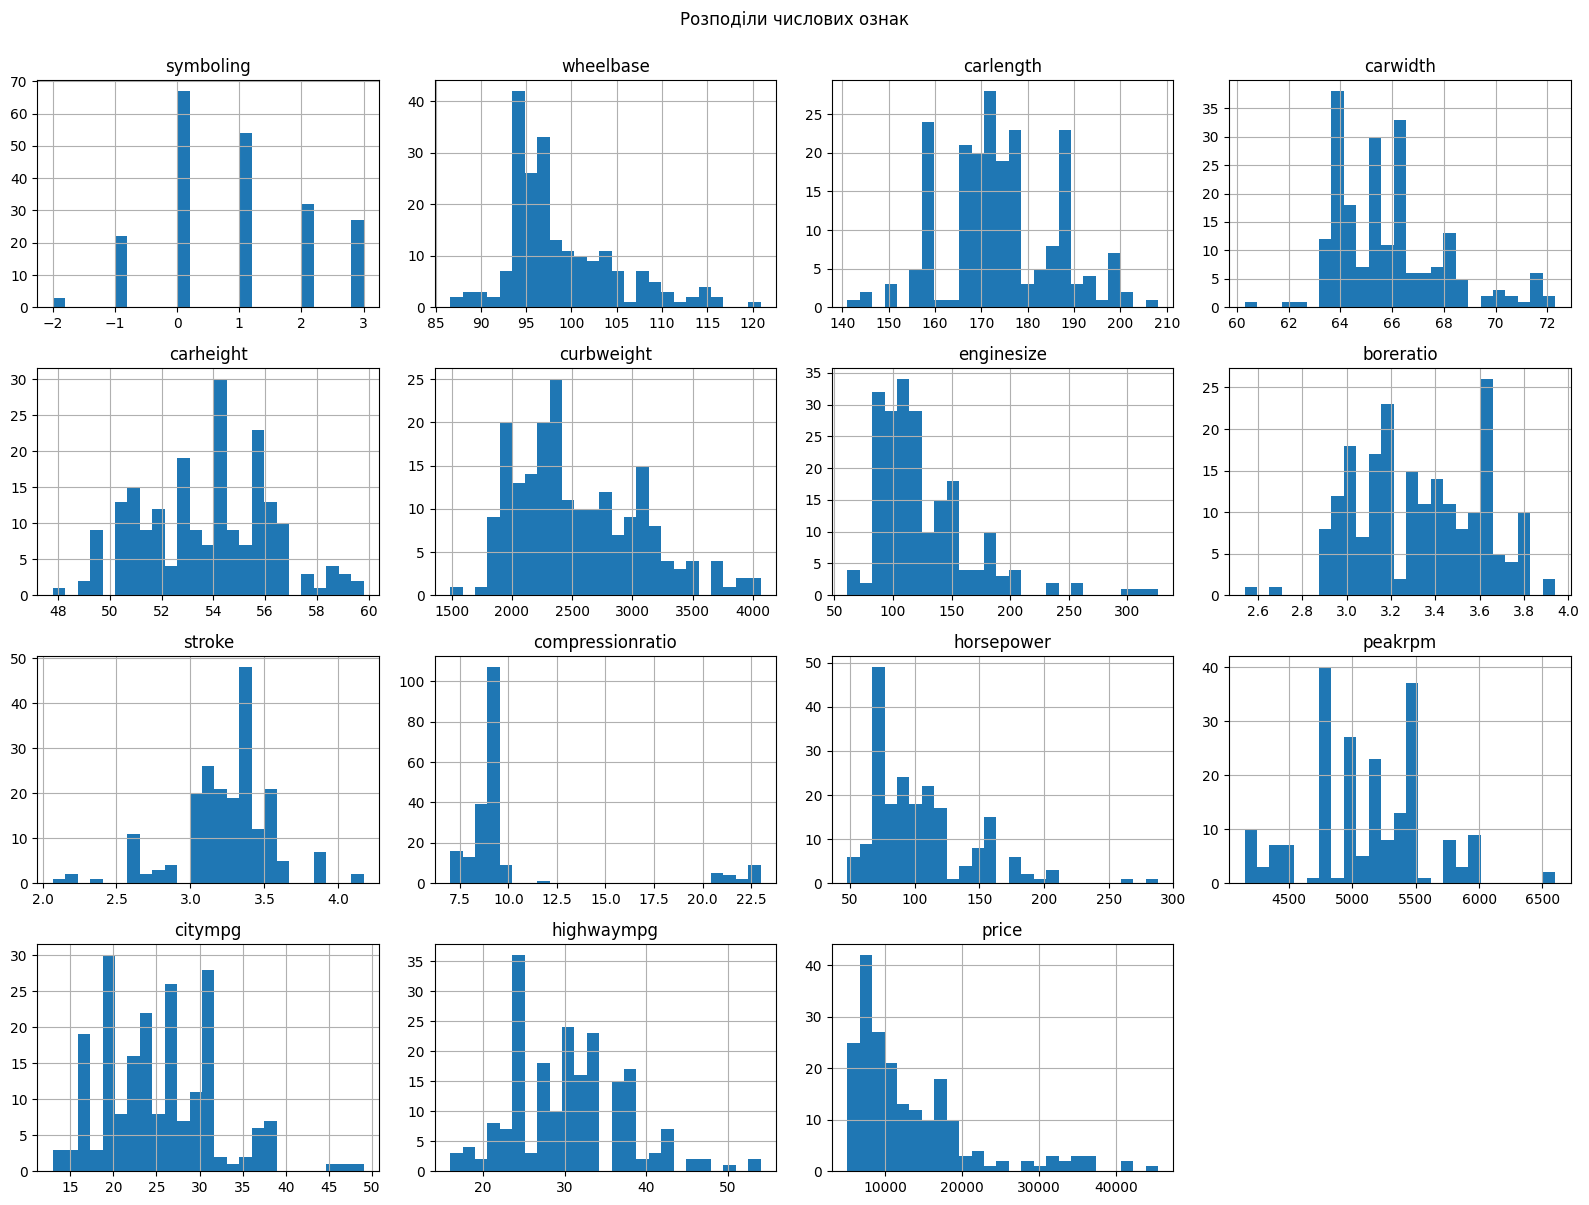

Коефіцієнти асиметрії:
compressionratio    2.611
enginesize          1.948
price               1.778
horsepower          1.405
wheelbase           1.050
carwidth            0.904
stroke             -0.690
curbweight          0.681
citympg             0.664
highwaympg          0.540
symboling           0.211
carlength           0.156
peakrpm             0.075
carheight           0.063
boreratio           0.020
dtype: float64

Найбільш асиметричні ознаки: ['compressionratio', 'enginesize', 'price']


In [10]:
num_cols_all = df_model.select_dtypes(include='number').columns.tolist()

df_model[num_cols_all].hist(bins=25, figsize=(16, 12))
plt.suptitle('Розподіли числових ознак', y=1.0)
plt.tight_layout()
plt.show()

skew_orig = df_model[num_cols_all].skew().sort_values(key=np.abs, ascending=False)
print('Коефіцієнти асиметрії:')
print(skew_orig.round(3))
print('\nНайбільш асиметричні ознаки:', list(skew_orig.index[:3]))

In [11]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns='price')
y = df_model['price']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=RANDOM_STATE)

X_train_raw = X_train.copy()

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('car_ID у train:', id_train.shape[0], '| у test:', id_test.shape[0])

Train: (164, 24) | Test: (41, 24)
car_ID у train: 164 | у test: 41


In [12]:
continuous_cols = [c for c in X_train.select_dtypes(include='number').columns if c != 'symboling']

rows, bounds = [], {}
for c in continuous_cols:
    q1, q3 = X_train[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bounds[c] = (lo, hi)
    n_out = ((X_train[c] < lo) | (X_train[c] > hi)).sum()
    rows.append((c, round(lo, 3), round(hi, 3), n_out))
outl = pd.DataFrame(rows, columns=['ознака', 'нижня межа', 'верхня межа', 'викидів у train'])
display(outl.sort_values('викидів у train', ascending=False))


for c, (lo, hi) in bounds.items():
    X_train[c] = X_train[c].clip(lo, hi)
    X_test[c] = X_test[c].clip(lo, hi)

print('Рядки не видалялись. Викиди обмежено межами IQR, обчисленими за train.')

,ознака,нижня межа,верхня межа,викидів у train
8,compressionratio,7.400,10.600,20
7,stroke,2.660,3.860,16
2,carwidth,60.425,70.425,10
9,horsepower,4.750,182.750,7
5,enginesize,33.500,205.500,7
0,wheelbase,83.100,113.500,6
10,peakrpm,3750.000,6550.000,2
12,highwaympg,11.500,47.500,1
6,boreratio,2.565,4.125,1
4,curbweight,998.625,4103.625,0


Рядки не видалялись. Викиди обмежено межами IQR, обчисленими за train.


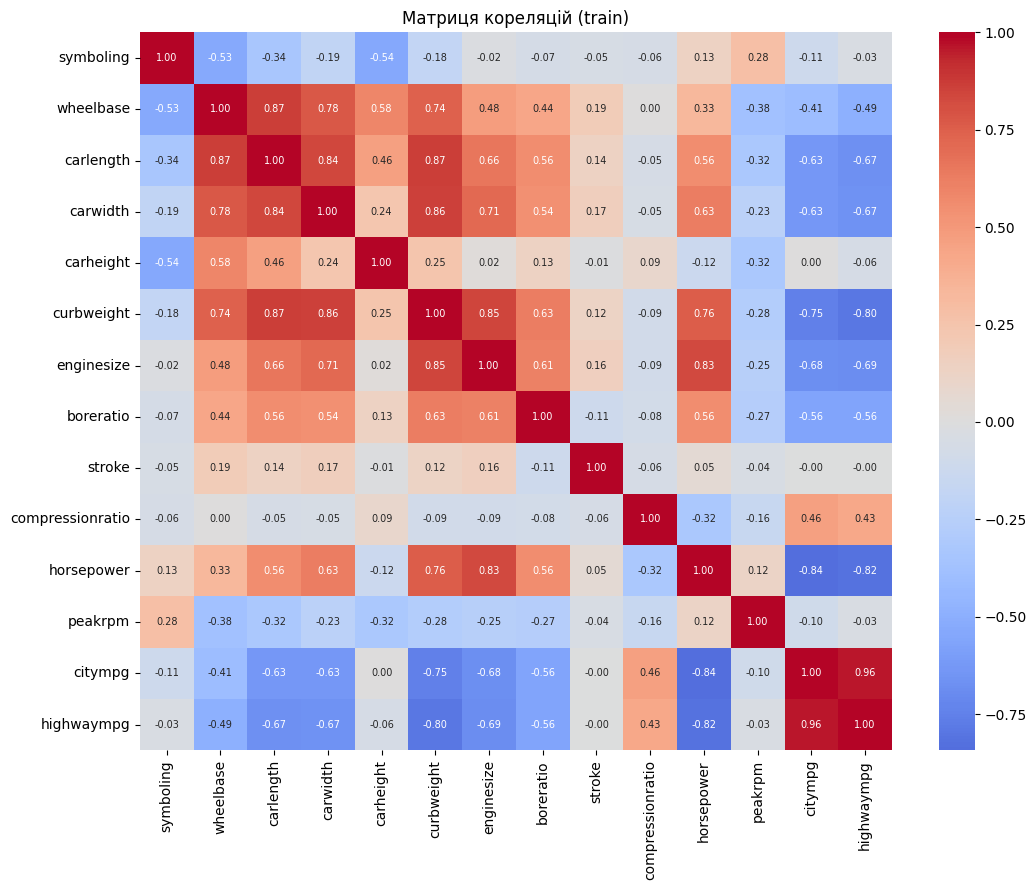

Сильно корельовані пари (|r| > 0.85):
  citympg ~ highwaympg: r=0.964 | |r з price|: 0.711 / 0.716 -> видаляємо citympg, залишаємо highwaympg
  wheelbase ~ carlength: r=0.867 | |r з price|: 0.504 / 0.652 -> видаляємо wheelbase, залишаємо carlength
  carlength ~ curbweight: r=0.866 | |r з price|: 0.652 / 0.824 -> видаляємо carlength, залишаємо curbweight
  carwidth ~ curbweight: r=0.858 | |r з price|: 0.732 / 0.824 -> видаляємо carwidth, залишаємо curbweight

Ознаки, що видаляються: ['carlength', 'carwidth', 'citympg', 'wheelbase']
Залишилось ознак: 20


In [13]:
from itertools import combinations

num_feats = X_train.select_dtypes(include='number').columns.tolist()
corr = X_train[num_feats].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Матриця кореляцій (train)')
plt.tight_layout()
plt.show()

target_corr = X_train[num_feats].corrwith(y_train).abs()

pairs = [(a, b, corr.loc[a, b]) for a, b in combinations(num_feats, 2) if abs(corr.loc[a, b]) > 0.85]
pairs.sort(key=lambda t: -abs(t[2]))

to_drop = set()
print('Сильно корельовані пари (|r| > 0.85):')
for a, b, r in pairs:
    if a in to_drop or b in to_drop:
        continue
    drop = a if target_corr[a] < target_corr[b] else b
    keep = b if drop == a else a
    to_drop.add(drop)
    print(f'  {a} ~ {b}: r={r:.3f} | |r з price|: {target_corr[a]:.3f} / {target_corr[b]:.3f} -> видаляємо {drop}, залишаємо {keep}')

to_drop = sorted(to_drop)
print('\nОзнаки, що видаляються:', to_drop)

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)
print('Залишилось ознак:', X_train.shape[1])

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

cont_cols = [c for c in continuous_cols if c in X_train.columns]
disc_cols = [c for c in ['symboling'] if c in X_train.columns]
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

print('Неперервні:', cont_cols)
print('Дискретна:', disc_cols)
print('Категоріальні:', cat_cols)

cont_pipe = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scaler', StandardScaler()),
])

preprocessor = ColumnTransformer([
    ('cont', cont_pipe, cont_cols),
    ('disc', StandardScaler(), disc_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])

Неперервні: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна: ['symboling']
Категоріальні: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']


In [15]:
Xc_tr = cont_pipe.fit_transform(X_train[cont_cols])     # fit тільки на train
Xc_tr = pd.DataFrame(Xc_tr, columns=cont_cols, index=X_train.index)

skew_cmp = pd.DataFrame({
    'початкова (train)': X_train_raw[cont_cols].skew(),
    'після IQR-обмеження': X_train[cont_cols].skew(),
    'після Yeo-Johnson+Scaler': Xc_tr.skew(),
}).round(3)
display(skew_cmp)

mean_abs = skew_cmp.abs().mean().round(3)
print('Середня |асиметрія|:')
print(mean_abs)

,початкова (train),після IQR-обмеження,після Yeo-Johnson+Scaler
carheight,0.028,0.028,-0.005
curbweight,0.712,0.712,0.050
enginesize,2.050,0.962,0.045
boreratio,0.050,0.063,-0.006
stroke,-0.755,-0.398,0.016
compressionratio,2.737,0.056,0.005
horsepower,1.546,0.851,0.066
peakrpm,0.067,0.040,-0.004
highwaympg,0.290,0.244,-0.012


Середня |асиметрія|:
початкова (train)           0.915
після IQR-обмеження         0.373
після Yeo-Johnson+Scaler    0.023
dtype: float64


In [16]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor

base_models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Lasso': Lasso(alpha=1.0, max_iter=50000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),

    'SVR': TransformedTargetRegressor(regressor=SVR(kernel='rbf', C=10, epsilon=0.1),
                                      transformer=StandardScaler()),
}

pipelines = {name: Pipeline([('prep', preprocessor), ('model', m)])
             for name, m in base_models.items()}
print(list(pipelines.keys()))

['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting', 'SVR']


In [17]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

preds, rows = {}, []
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    p_te = pipe.predict(X_test)
    p_tr = pipe.predict(X_train)
    preds[name] = p_te
    rows.append({
        'Модель': name,
        'R2': r2_score(y_test, p_te),
        'MAE': mean_absolute_error(y_test, p_te),
        'MSE': mean_squared_error(y_test, p_te),
        'MAPE, %': mean_absolute_percentage_error(y_test, p_te) * 100,
        'R2 (train)': r2_score(y_train, p_tr),
    })

results = pd.DataFrame(rows).sort_values('R2', ascending=False).reset_index(drop=True)
display(results.round(3))

,Модель,R2,MAE,MSE,"MAPE, %",R2 (train)
0,Random Forest,0.955,1311.091,3.519785e+06,9.642,0.985
1,Gradient Boosting,0.930,1727.404,5.492942e+06,12.050,0.993
2,SVR,0.929,1668.311,5.574315e+06,15.540,0.988
3,Linear Regression,0.879,2156.098,9.518236e+06,16.376,0.960
4,Lasso,0.878,2105.214,9.612671e+06,15.134,0.960
5,Ridge,0.854,2367.224,1.154249e+07,18.193,0.948


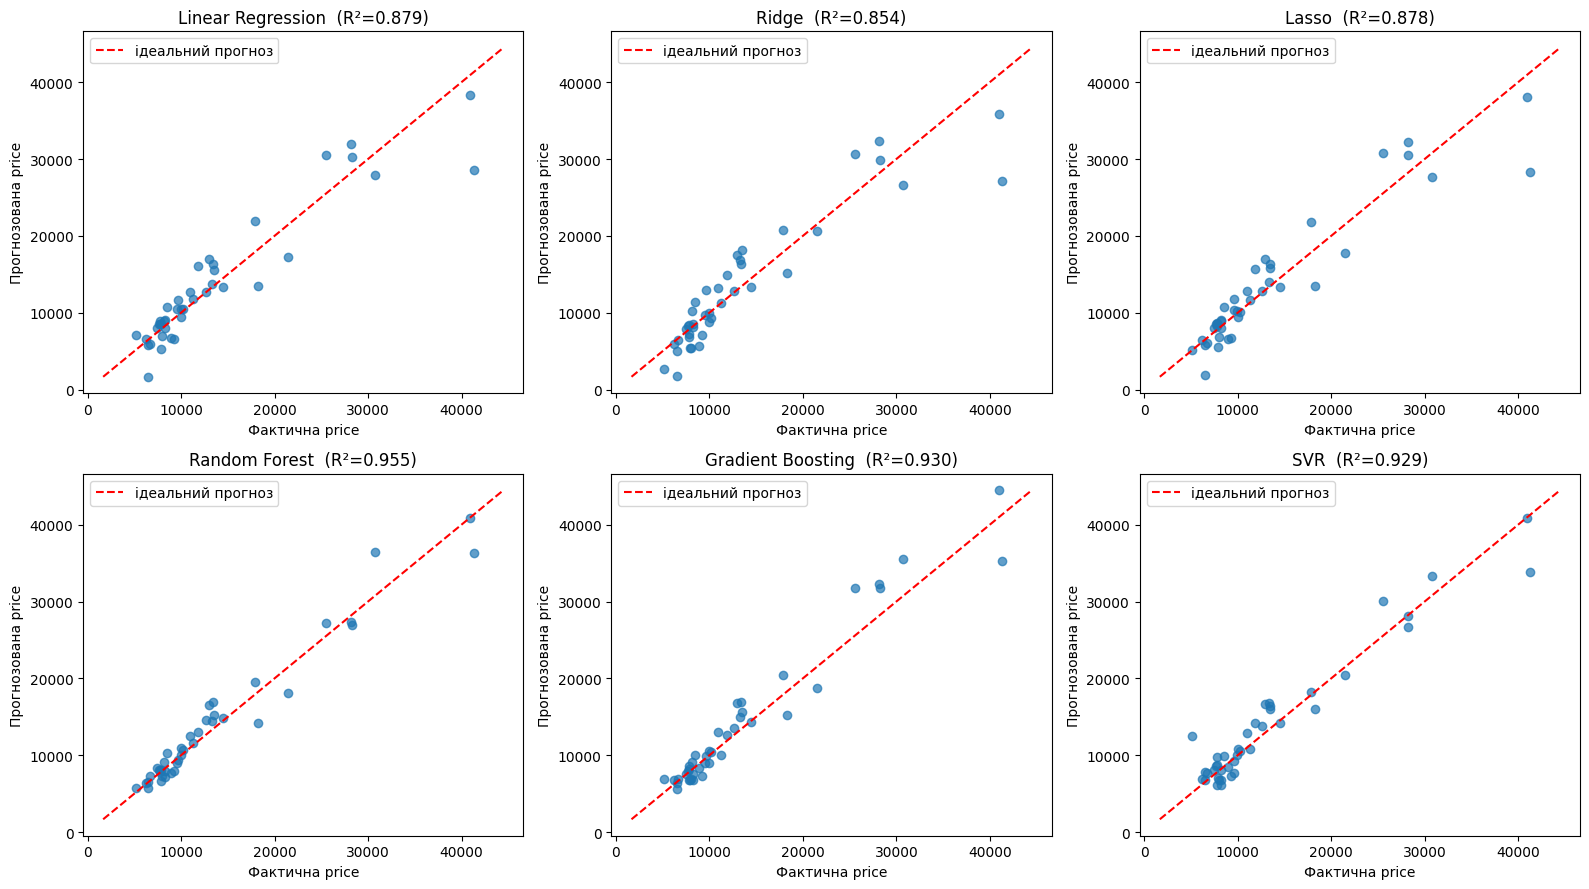

Найбільша помилка для кожної моделі:
  Linear Regression: car_ID=17, факт=41315, прогноз=28634, помилка=12681
  Ridge: car_ID=17, факт=41315, прогноз=27195, помилка=14120
  Lasso: car_ID=17, факт=41315, прогноз=28267, помилка=13048
  Random Forest: car_ID=16, факт=30760, прогноз=36383, помилка=5623
  Gradient Boosting: car_ID=68, факт=25552, прогноз=31812, помилка=6260
  SVR: car_ID=17, факт=41315, прогноз=33812, помилка=7503


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
lims = [min(y_test.min(), min(p.min() for p in preds.values())),
        max(y_test.max(), max(p.max() for p in preds.values()))]
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test, p, alpha=0.7)
    ax.plot(lims, lims, 'r--', label='ідеальний прогноз')
    ax.set_title(f'{name}  (R²={r2_score(y_test, p):.3f})')
    ax.set_xlabel('Фактична price')
    ax.set_ylabel('Прогнозована price')
    ax.legend()
plt.tight_layout()
plt.show()

print('Найбільша помилка для кожної моделі:')
for name, p in preds.items():
    err = (y_test - p).abs()
    i = err.idxmax()
    print(f'  {name}: car_ID={id_test.loc[i]}, факт={y_test.loc[i]:.0f}, прогноз={p[y_test.index.get_loc(i)]:.0f}, помилка={err.loc[i]:.0f}')

In [19]:
sample_idx = X_test.sample(n=10, random_state=RANDOM_STATE).index
rf = pipelines['Random Forest']
pred_s = rf.predict(X_test.loc[sample_idx])

table = pd.DataFrame({
    'car_ID': id_test.loc[sample_idx].values,
    'фактична ціна': y_test.loc[sample_idx].values,
    'прогнозована ціна': pred_s,
})
table['абсолютна помилка'] = (table['фактична ціна'] - table['прогнозована ціна']).abs()
table['APE, %'] = table['абсолютна помилка'] / table['фактична ціна'] * 100
display(table.round(2))
print(f"Середня абсолютна помилка: {table['абсолютна помилка'].mean():.0f} | середня APE: {table['APE, %'].mean():.2f}%")

,car_ID,фактична ціна,прогнозована ціна,абсолютна помилка,"APE, %"
0,26,6692.0,7322.24,630.24,9.42
1,176,9988.0,10929.02,941.02,9.42
2,148,10198.0,10695.45,497.45,4.88
3,17,41315.0,36368.71,4946.29,11.97
4,69,28248.0,26909.69,1338.31,4.74
5,147,7463.0,8294.29,831.29,11.14
6,144,9960.0,10062.71,102.71,1.03
7,85,14489.0,14825.76,336.76,2.32
8,195,12940.0,16563.30,3623.30,28.00
9,160,7788.0,7827.16,39.16,0.50


Середня абсолютна помилка: 1329 | середня APE: 8.34%


In [20]:
best = results.iloc[0]
worst = results.iloc[-1]
print(f"Найкраща модель за R²: {best['Модель']} (R²={best['R2']:.3f}, MAE={best['MAE']:.0f}, MAPE={best['MAPE, %']:.2f}%)")
print(f"Найгірша модель: {worst['Модель']} (R²={worst['R2']:.3f})")
results['розрив R2 train-test'] = results['R2 (train)'] - results['R2']
print('\nМоделі з розривом train-test > 0.10 (можливе перенавчання):')
print(results.loc[results['розрив R2 train-test'] > 0.10, ['Модель', 'R2 (train)', 'R2', 'розрив R2 train-test']].round(3).to_string(index=False))

Найкраща модель за R²: Random Forest (R²=0.955, MAE=1311, MAPE=9.64%)
Найгірша модель: Ridge (R²=0.854)

Моделі з розривом train-test > 0.10 (можливе перенавчання):
Empty DataFrame
Columns: [Модель, R2 (train), R2, розрив R2 train-test]
Index: []
